HYPERMART DATASET

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv('../Datasets/Hypermart.csv',encoding='latin1')

In [4]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [5]:
# Drop duplicate Cols
print(df.columns[df.columns.duplicated()])
# there are no dupllicate cols

Index([], dtype='object')


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [7]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [8]:
# Drop duplicate rows
df=df.drop_duplicates()

In [9]:
df.info()
# No of rows remains same before and after dropping duplicates hence there are no duplicate rows

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [10]:
# Convert date to date time format
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

In [11]:
# Check for inconsistencies
print("Negative Sales:", (df["Sales"] < 0).sum())
print("Negative Quantity:", (df["Quantity"] < 0).sum())
print("Invalid Discounts:", ((df["Discount"] < 0) | (df["Discount"] > 1)).sum())
print("Invalid Ship Dates:", (df["Ship Date"] < df["Order Date"]).sum())
# No inconsistencies

Negative Sales: 0
Negative Quantity: 0
Invalid Discounts: 0
Invalid Ship Dates: 0


In [12]:
df1=df.groupby('Category')[['Sales','Profit']].mean().reset_index()

In [13]:
df1=df1.rename(columns={'Sales':'Average_Sales','Profit':'Average_Profit'})

In [14]:
df1
# Average sales and profits for each category

,Category,Average_Sales,Average_Profit
0,Furniture,349.834887,8.699327
1,Office Supplies,119.324101,20.327050
2,Technology,452.709276,78.752002


In [15]:
df3=df.merge(df1,on='Category')

In [16]:
df3

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Average_Sales,Average_Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,349.834887,8.699327
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,349.834887,8.699327
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,119.324101,20.327050
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,349.834887,8.699327
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,119.324101,20.327050
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,9990,CA-2014-110422,2014-01-21,2014-01-23,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3,0.20,4.1028,349.834887,8.699327
9990,9991,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.9600,2,0.00,15.6332,349.834887,8.699327
9991,9992,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.5760,2,0.20,19.3932,452.709276,78.752002
9992,9993,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.6000,4,0.00,13.3200,119.324101,20.327050


In [17]:
df3.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit',
       'Average_Sales', 'Average_Profit'],
      dtype='object')

In [18]:
df4=df3[(df3['Sales']>df3['Average_Sales']) & ((df3['Profit']<df3['Average_Profit']) | (df3['Profit']<0))][['Product Name','Sales','Profit','Segment']]
# Filtering rows with high sales but low profits

In [19]:
print('Top 10 products with max sales but low proits')
df4.sort_values(by=['Sales','Profit'],ascending=[False,True]).head(10)

Top 10 products with max sales but low proits


,Product Name,Sales,Profit,Segment
2697,Cisco TelePresence System EX90 Videoconferenci...,22638.480,-1811.0784,Home Office
165,Lexmark MX611dhe Monochrome Laser Printer,8159.952,-1359.9920,Consumer
683,Cubify CubeX 3D Printer Triple Head Print,7999.980,-3839.9904,Corporate
1803,Martin Yale Chadless Opener Electric Letter Op...,4663.736,-1049.3406,Consumer
7772,Cubify CubeX 3D Printer Double Head Print,4499.985,-6599.9780,Consumer
7243,HON 5400 Series Task Chairs for Big and Tall,4416.174,-630.8820,Consumer
9639,Chromcraft Bull-Nose Wood Oval Conference Tabl...,4297.644,-1862.3124,Consumer
6535,DMI Eclipse Executive Suite Bookcases,4007.840,-50.0980,Consumer
5198,High Speed Automatic Electric Letter Opener,3930.072,-786.0144,Consumer
27,"Riverside Palais Royal Lawyers Bookcase, Royal...",3083.430,-1665.0522,Consumer


In [20]:
category_wise=df.groupby('Category')['Sales'].sum().reset_index(name='Total Sales')

In [21]:
category_wise=category_wise.sort_values(by='Total Sales',ascending=False)
category_wise
# Category wise total sales

,Category,Total Sales
2,Technology,836154.0330
0,Furniture,741999.7953
1,Office Supplies,719047.0320


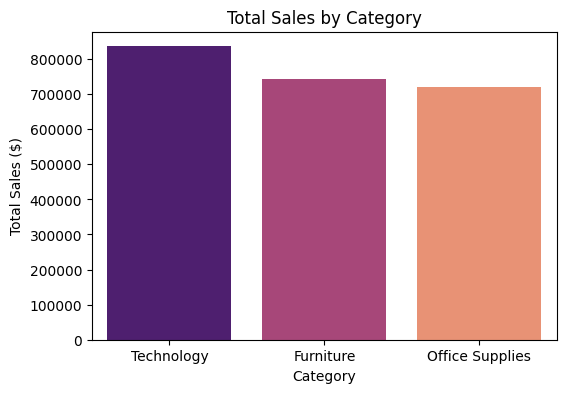

In [22]:
plt.figure(figsize=(6,4))
sns.barplot(x=category_wise['Category'],y=category_wise['Total Sales'],hue=category_wise['Category'],palette='magma')
plt.title("Total Sales by Category")
plt.ylabel("Total Sales ($)")
plt.xlabel("Category")
plt.show()

In [23]:
sub_category_wise=df.groupby('Sub-Category')['Sales'].sum().reset_index(name='Total Sales')

In [24]:
sub_category_wise=sub_category_wise.sort_values(by='Total Sales',ascending=False)
sub_category_wise.head(5)

,Sub-Category,Total Sales
13,Phones,330007.054
5,Chairs,328449.103
14,Storage,223843.608
16,Tables,206965.532
3,Binders,203412.733


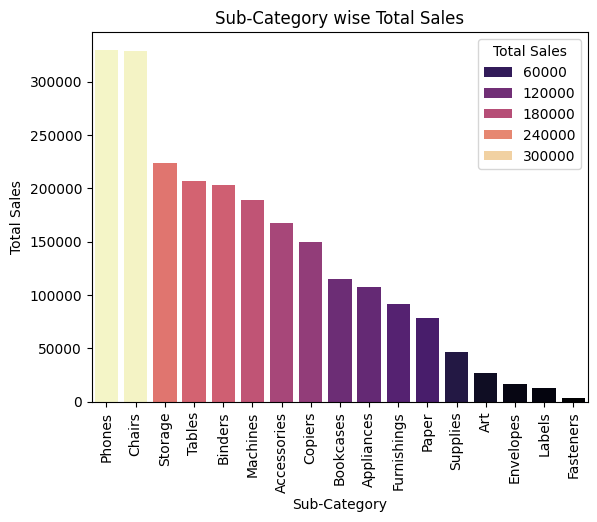

In [25]:
sns.barplot(data=sub_category_wise,x='Sub-Category',y='Total Sales',palette='magma',hue='Total Sales')
plt.title('Sub-Category wise Total Sales')
plt.xticks(rotation=90)
plt.show()

In [26]:
print(pd.unique(df['Ship Mode']))

['Second Class' 'Standard Class' 'First Class' 'Same Day']


In [27]:
orders_df=df['Ship Mode'].value_counts().reset_index(name='Total orders')
# Standard shippping mode was used most no of times
orders_df

,Ship Mode,Total orders
0,Standard Class,5968
1,Second Class,1945
2,First Class,1538
3,Same Day,543


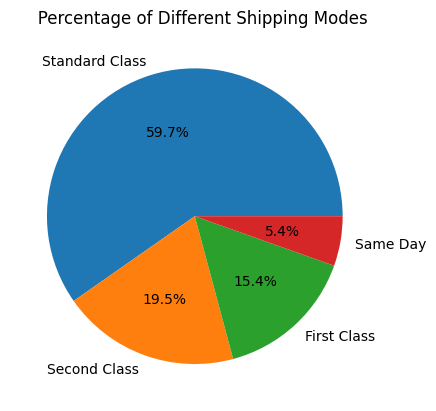

In [28]:
plt.pie(orders_df['Total orders'],labels=orders_df['Ship Mode'],autopct='%1.1f%%')
plt.title("   Percentage of Different Shipping Modes")
plt.show()

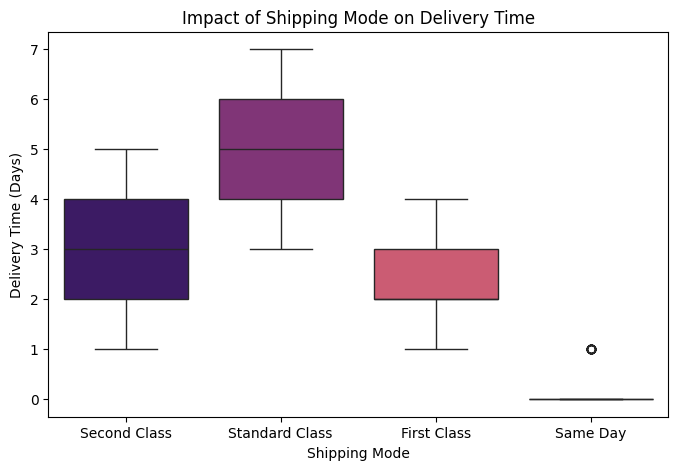

In [29]:
# Impact of Shipping Mode on Delivery Time
df["Delivery Time (Days)"] = (df["Ship Date"] - df["Order Date"]).dt.days
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Ship Mode"], y=df["Delivery Time (Days)"],hue=df['Ship Mode'],palette="magma")
plt.title("Impact of Shipping Mode on Delivery Time")
plt.ylabel("Delivery Time (Days)")
plt.xlabel("Shipping Mode")
plt.show()

In [30]:
print(pd.unique(df['Segment']))

['Consumer' 'Corporate' 'Home Office']


In [31]:
df1=df.groupby('Segment')[['Sales','Profit']].sum()

In [32]:
df1=df1.rename(columns={'Sales':'Total_Sales','Profit':'Total_Profit'})
df1
# Segment wise total sales and profits

,Total_Sales,Total_Profit
Segment,,
Consumer,1.161401e+06,134119.2092
Corporate,7.061464e+05,91979.1340
Home Office,4.296531e+05,60298.6785


C:\Users\Samarth\AppData\Local\Temp\ipykernel_16640\1715014003.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df1,ax=ax[0],x='Segment',y='Total_Sales',palette='magma')
C:\Users\Samarth\AppData\Local\Temp\ipykernel_16640\1715014003.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df1,ax=ax[1],x='Segment',y='Total_Profit',palette='magma')


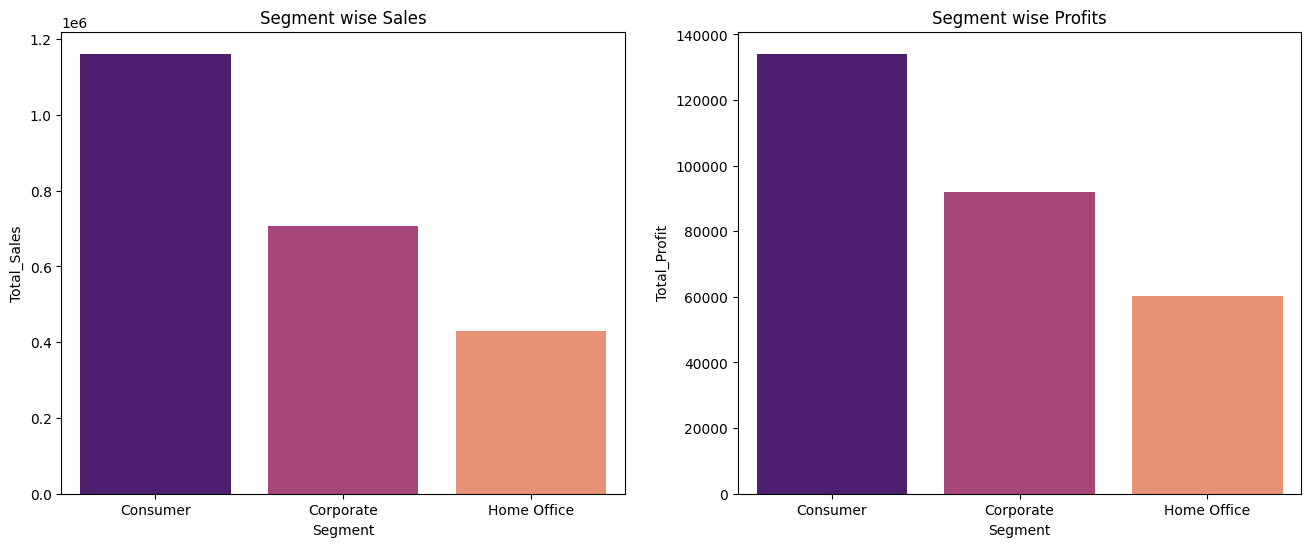

In [33]:
fig,ax=plt.subplots(1,2,figsize=(16, 6))
sns.barplot(data=df1,ax=ax[0],x='Segment',y='Total_Sales',palette='magma')
sns.barplot(data=df1,ax=ax[1],x='Segment',y='Total_Profit',palette='magma')
ax[0].set_title('Segment wise Sales')
ax[1].set_title('Segment wise Profits')
plt.show()

In [34]:
df1=df.groupby(['Segment','Customer ID']).size().reset_index(name='Purchase_Count')

In [35]:
df1
# Segment wise total purchase count of each customer

,Segment,Customer ID,Purchase_Count
0,Consumer,AA-10315,11
1,Consumer,AA-10375,15
2,Consumer,AA-10480,12
3,Consumer,AA-10645,18
4,Consumer,AB-10015,6
...,...,...,...
788,Home Office,TW-21025,12
789,Home Office,VF-21715,11
790,Home Office,VM-21685,12
791,Home Office,VP-21730,5


In [36]:
df2=df1.groupby('Segment')['Purchase_Count'].mean().reset_index(name='Average purchase rate')
# Average purchase rate of each segment

In [37]:
df2.sort_values(by='Average purchase rate',ascending=False)

,Segment,Average purchase rate
1,Corporate,12.796610
0,Consumer,12.691932
2,Home Office,12.047297


In [38]:
discount_effect = df.groupby(["Segment", "Discount"])[["Sales"]].sum().reset_index()
discount_effect.head()
# Total sales for each segment and each discount rate

,Segment,Discount,Sales
0,Consumer,0.00,532517.100
1,Consumer,0.10,30799.548
2,Consumer,0.15,14728.018
3,Consumer,0.20,394133.984
4,Consumer,0.30,63155.855


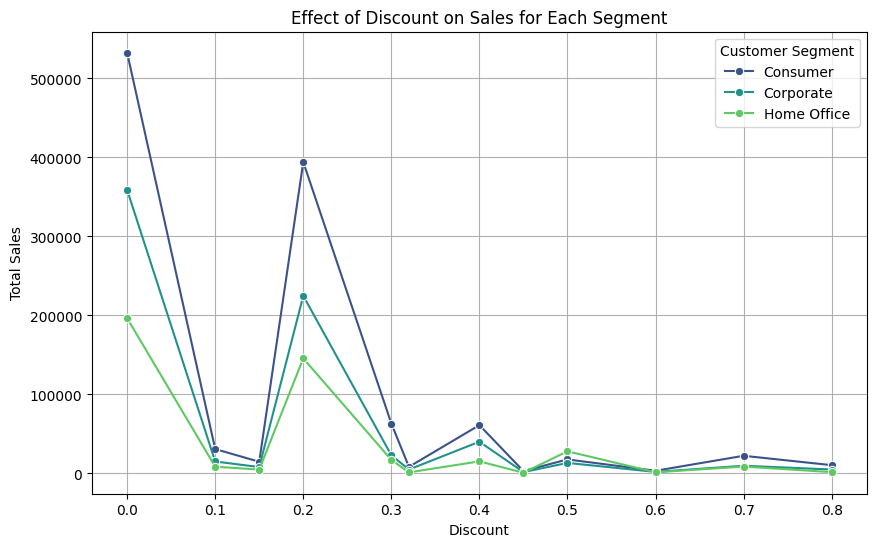

In [49]:
plt.figure(figsize=(10, 6))
sns.lineplot(data=discount_effect, x="Discount", y="Sales", hue="Segment", marker="o",palette='viridis')
plt.title("Effect of Discount on Sales for Each Segment")
plt.xlabel("Discount")
plt.ylabel("Total Sales")
plt.legend(title="Customer Segment")
plt.grid()
plt.show()

In [40]:
print(df['Sales'].corr(df['Profit']))
# Corelation factor between Sales and Profits

0.4790643497377061


In [41]:
region=df.groupby("Region")[["Sales", "Profit"]].sum().reset_index()
region= region.sort_values(by=["Sales", "Profit"], ascending=[False, False])
region
# Region wise sales and profits

,Region,Sales,Profit
3,West,725457.8245,108418.4489
1,East,678781.2400,91522.7800
0,Central,501239.8908,39706.3625
2,South,391721.9050,46749.4303


C:\Users\Samarth\AppData\Local\Temp\ipykernel_16640\1591288375.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Region',y='Sales',data=region,palette='viridis')


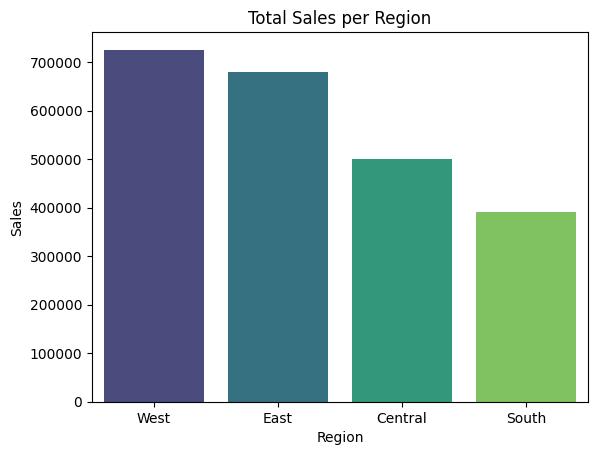

In [42]:
sns.barplot(x='Region',y='Sales',data=region,palette='viridis')
plt.title('Total Sales per Region')
plt.xlabel('Region')
plt.ylabel('Sales')
plt.show()

C:\Users\Samarth\AppData\Local\Temp\ipykernel_16640\341634484.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Region',y='Profit',data=region,palette='viridis')


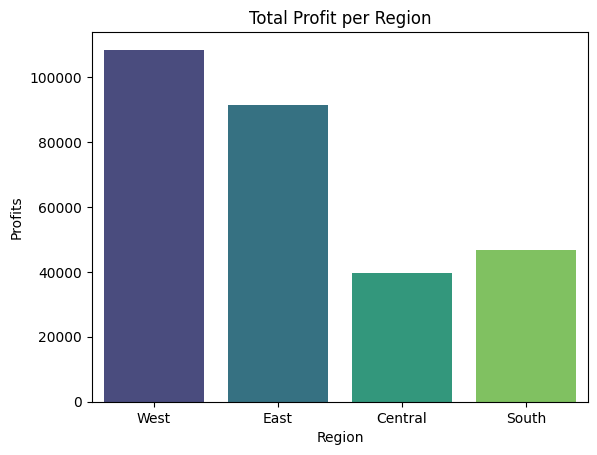

In [43]:
sns.barplot(x='Region',y='Profit',data=region,palette='viridis')
plt.title('Total Profit per Region')
plt.xlabel('Region')
plt.ylabel('Profits')
plt.show()

In [44]:
segment_perfomance=df.groupby('Segment')[['Sales','Profit']].sum()
segment_perfomance

,Sales,Profit
Segment,,
Consumer,1.161401e+06,134119.2092
Corporate,7.061464e+05,91979.1340
Home Office,4.296531e+05,60298.6785


In [45]:
segment_region_performance = df.groupby(["Region", "Segment"])[["Sales", "Profit"]].sum().reset_index()
segment_region_performance = segment_region_performance.sort_values(by=['Profit'], ascending=[False])
segment_region_performance
# Region and Segment wise total sales and profits

,Region,Segment,Sales,Profit
9,West,Consumer,362880.7730,57450.6040
3,East,Consumer,350908.1670,41190.9843
10,West,Corporate,225855.2745,34437.4299
6,South,Consumer,195580.9710,26913.5728
5,East,Home Office,127463.7260,26709.2168
4,East,Corporate,200409.3470,23622.5789
1,Central,Corporate,157995.8128,18703.9020
11,West,Home Office,136721.7770,16530.4150
7,South,Corporate,121885.9325,15215.2232
2,Central,Home Office,91212.6440,12438.4124


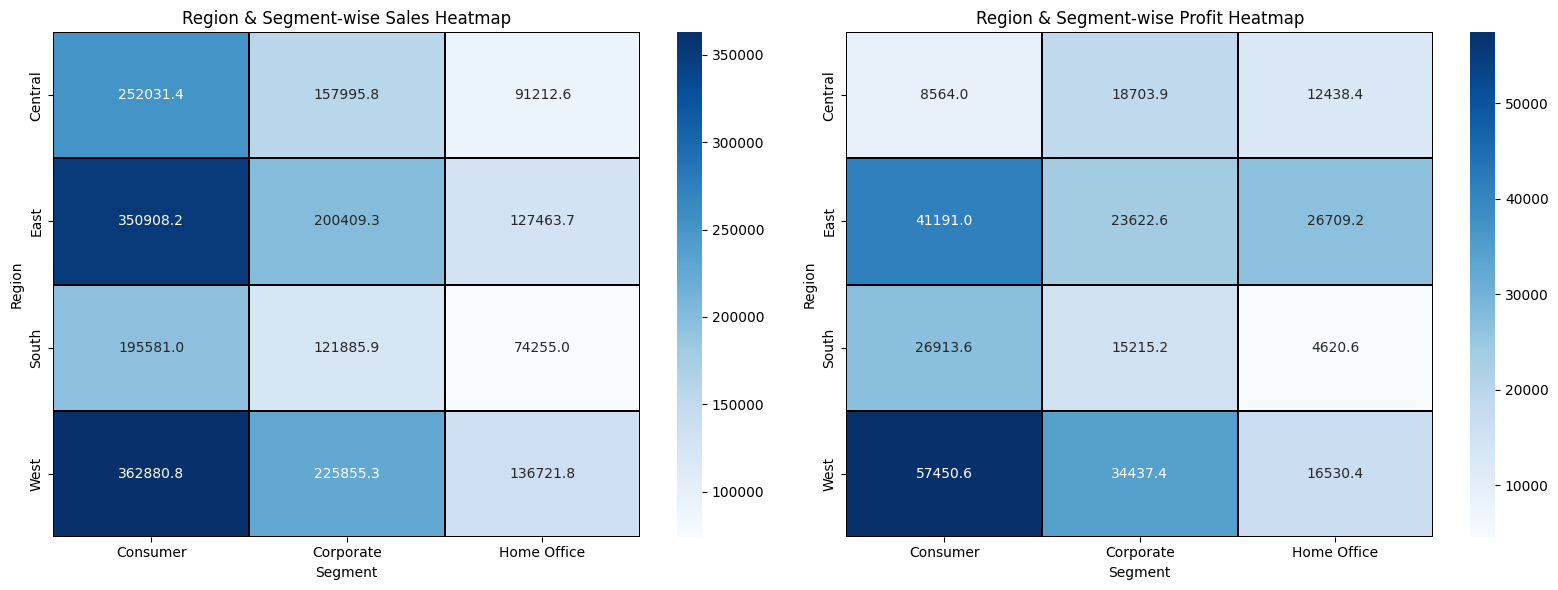

In [52]:
fig,ax=plt.subplots(1,2,figsize=(16, 6))
pivot_df1 = segment_region_performance.pivot(index='Region', columns='Segment', values='Sales')
pivot_df2 = segment_region_performance.pivot(index='Region', columns='Segment', values='Profit')
sns.heatmap(pivot_df1,ax=ax[0],annot=True, cmap='Blues', fmt=".1f",linewidth=0.1,linecolor='black')
sns.heatmap(pivot_df2,ax=ax[1],annot=True, cmap='Blues', fmt=".1f",linewidth=0.1,linecolor='black')
ax[0].set_title("Region & Segment-wise Sales Heatmap")
ax[1].set_title("Region & Segment-wise Profit Heatmap") 
plt.tight_layout()
plt.show()

In [47]:
region["Profit Margin (%)"] = (region["Profit"]/region["Sales"]) * 100
region
# Region wise low sales but high profit

,Region,Sales,Profit,Profit Margin (%)
3,West,725457.8245,108418.4489,14.944831
1,East,678781.2400,91522.7800,13.483399
0,Central,501239.8908,39706.3625,7.921629
2,South,391721.9050,46749.4303,11.934342


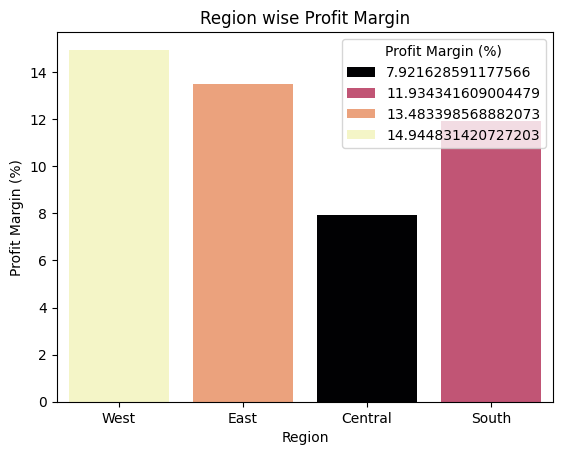

In [48]:
sns.barplot(data=region,x='Region',y='Profit Margin (%)',palette='magma',hue='Profit Margin (%)')
plt.title('Region wise Profit Margin')
plt.show()